## Notebook 4 – Univariate Analysis

Univariate analysis is a statistical technique used to analyze one variable at a time to understand its distribution, central tendency, variability, and other characteristics.

- Uni = One
- Variate = Variable

Therefore, univariate analysis means analyzing a single variable at a time.

#### Example

Suppose you have a dataset containing the ages of five people.

| Person | Age |
| ------ | --: |
| Hari   |  22 |
| Kumar  |  25 |
| Ravi   |  23 |
| Priya  |  24 |
| Arun   |  26 |


If you analyze only the Age column to understand the average age, minimum age, maximum age, and distribution of ages, you are performing univariate analysis.

**You are studying just one variable: Age.**

- Univariate: Analyze only Salary.
- Bivariate: Analyze Experience and Salary together.
- Multivariate: Analyze Experience, Salary, and Age together.

The key difference is the number of variables analyzed together.

#### Numerical Variables

#### Example:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Salary": [20000, 25000, 25000, 30000, 35000, 40000, 50000, 80000]
}

df = pd.DataFrame(data)

df

,Salary
0,20000
1,25000
2,25000
3,30000
4,35000
5,40000
6,50000
7,80000


#### Part 1: Descriptive Statistics

#### 1. Mean
 The mean is the average of all the values in a dataset. It is calculated by adding all values and dividing their sum by the total number of values.

### Formula $$ \bar{x} = \frac{\sum_{i=1}^{n} x_i}{n} $$ 
Where: 
- $\bar{x}$ = Mean 
- $x_i$ = Each individual value
- $n$ = Total number of observations
- $\sum$ = Summation (addition of all values)

In [4]:
print(df["Salary"].mean())

38125.0


####  Median

The median is the middle value of a dataset after arranging its values in ascending or descending order.

If the number of observations is odd, the median is the middle value.
If the number of observations is even, the median is the average of the two middle values.

In [5]:
df["Salary"].median()

np.float64(32500.0)

#### Mode

The mode is the value that occurs most frequently in a dataset.

A dataset can have:

One mode

Multiple modes

No repeated values, meaning no unique most frequent value

In [6]:
df["Salary"].mode()

0    25000
Name: Salary, dtype: int64

#### Minimum and Maximum

- Minimum: The smallest value in a dataset.
- Maximum: The largest value in a dataset.

In [7]:
print("Minimum Salary:", df["Salary"].min())
print("Maximum Salary:", df["Salary"].max())

Minimum Salary: 20000
Maximum Salary: 80000


#### Range


Definition: Range is the difference between the maximum and minimum values in a dataset.

Formula:

Range = Xmax - Xmin
	​


In [8]:
salary_range = df["Salary"].max() - df["Salary"].min()

print("Salary Range:", salary_range)

Salary Range: 60000


#### Variance

Definition: Variance measures how far the values in a dataset spread out from their mean.

A small variance means the values are relatively close to the mean. A large variance means they are more spread out.

In [9]:
print("Population Variance:", df["Salary"].var(ddof=0))
print("Sample Variance:", df["Salary"].var())


Population Variance: 330859375.0
Sample Variance: 378125000.0


- ddof=0 calculates population variance.
- By default, Pandas uses ddof=1 for sample variance.

#### Standard Deviation

Definition: Standard deviation measures how spread out values are around their mean. It is the square root of variance.

In [10]:
print("Population Standard Deviation:", df["Salary"].std(ddof=0))
print("Sample Standard Deviation:", df["Salary"].std())

Population Standard Deviation: 18189.54026356906
Sample Standard Deviation: 19445.436482630055


#### Quartiles


Definition: Quartiles divide an ordered dataset into four parts, each containing approximately 25% of the observations.

- Q1: First quartile, or 25th percentile.
- Q2: Second quartile, or median (50th percentile).
- Q3: Third quartile, or 75th percentile.

In [11]:
print("Q1:", df["Salary"].quantile(0.25))
print("Q2:", df["Salary"].quantile(0.50))
print("Q3:", df["Salary"].quantile(0.75))

Q1: 25000.0
Q2: 32500.0
Q3: 42500.0


#### Percentiles

Definition: A percentile indicates the value at or below which a specified percentage of observations falls.

For example, the 90th percentile is a value at or below which approximately 90% of observations fall, according to the chosen percentile calculation method.

Suppose a student's exam score is at the 90th percentile.

**This means the score is at or above approximately 90% of the scores in the comparison group, depending on the percentile convention.**

It does not mean the student scored 90 marks out of 100.

In [12]:
print("25th Percentile:", df["Salary"].quantile(0.25))
print("50th Percentile:", df["Salary"].quantile(0.50))
print("90th Percentile:", df["Salary"].quantile(0.90))

25th Percentile: 25000.0
50th Percentile: 32500.0
90th Percentile: 58999.99999999999


#### Skewness

Definition: Skewness measures the asymmetry of a distribution.

Skewness is a statistical measure that describes the asymmetry of a data distribution around its mean.

In simple terms:

Skewness tells us whether the data is evenly distributed or stretched more toward one side.

| Type                                | Meaning                           | General Shape                          |
| ----------------------------------- | --------------------------------- | -------------------------------------- |
| Zero or approximately zero skewness | Relatively symmetric distribution | Both sides are similar                 |
| Positive skewness                   | Longer right tail                 | A few large values extend to the right |
| Negative skewness                   | Longer left tail                  | A few small values extend to the left  |


In [13]:
df["Salary"].skew()

np.float64(1.6596555855948718)

- Positive result → Right-skewed tendency.
- Negative result → Left-skewed tendency.
- Result near zero → More symmetric tendency.

#### Kurtosis

Definition: Kurtosis describes aspects of a distribution's tails and its tendency to produce extreme observations, relative to a normal distribution.

Pandas calculates excess kurtosis by default, for which a normal distribution has a value of approximately zero.

Imagine two salary datasets with similar means.

- Dataset A has few extreme salaries.
- Dataset B contains several unusually high or low salaries.

The second dataset may have higher kurtosis, depending on the overall distribution.

In [14]:
df["Salary"].kurt()

np.float64(2.932805136261183)

### Part 2: Visualizations

#### Histogram

A histogram displays the frequency of numerical observations across intervals called bins.

It helps you understand:

- Where values are concentrated.
- Whether the distribution is symmetric or skewed.
- Whether there are multiple peaks.
- Whether unusually high or low values may be present.

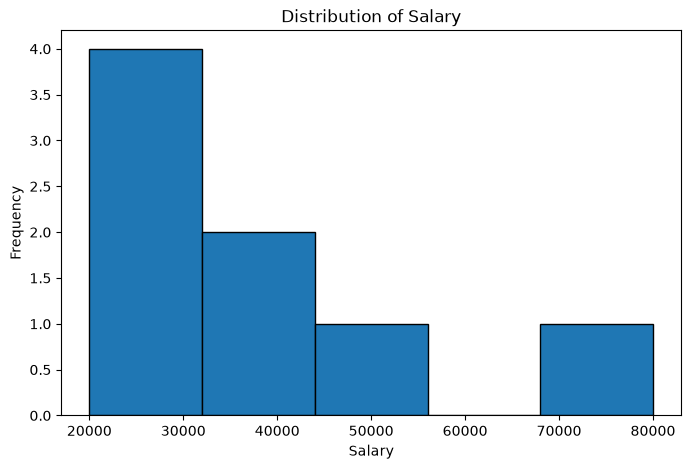

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["Salary"], bins=5, edgecolor="black")

plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.title("Distribution of Salary")

plt.show()

Each bar represents the number of observations within a particular salary interval.

The appearance of the histogram depends on the number and width of the bins.

#### KDE / Density Plot

KDE (Kernel Density Estimation) produces a smooth estimate of the distribution of a numerical variable.

Unlike a histogram, which uses bars and bins, a KDE plot uses a continuous curve.

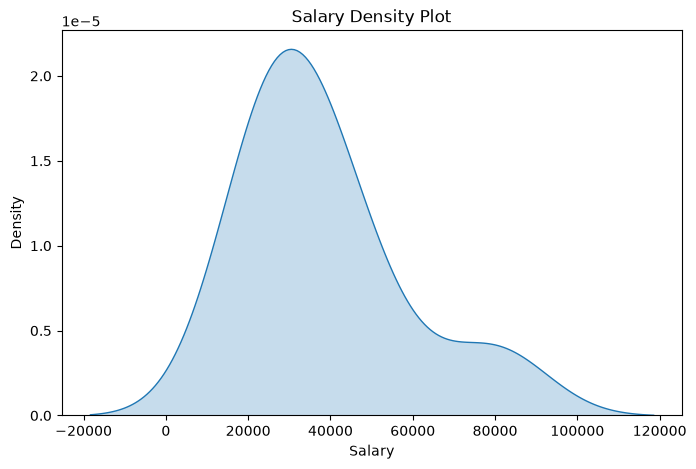

In [16]:
plt.figure(figsize=(8, 5))

sns.kdeplot(data=df, x="Salary", fill=True)

plt.xlabel("Salary")
plt.ylabel("Density")
plt.title("Salary Density Plot")

plt.show()

Interpretation:

- Peaks indicate regions where observations are concentrated.
- Wider areas indicate a broader spread of observations.
- Long tails can indicate skewness.

Important: KDE is an estimate, and its shape depends on the bandwidth. It can be misleading for very small datasets, such as our eight-row example. Use a larger dataset for a more informative density plot.

#### Box Plot

A box plot summarizes a numerical distribution using its quartiles, median, and potential outliers.

It displays:

Q1: 25th percentile.
    
Median: 50th percentile.
    
Q3: 75th percentile.
    
IQR: Difference between Q3 and Q1.
    
Whiskers: Extend to the most extreme observations within the conventional 1.5 × IQR limits.
    
Potential outliers: Points beyond the whiskers.

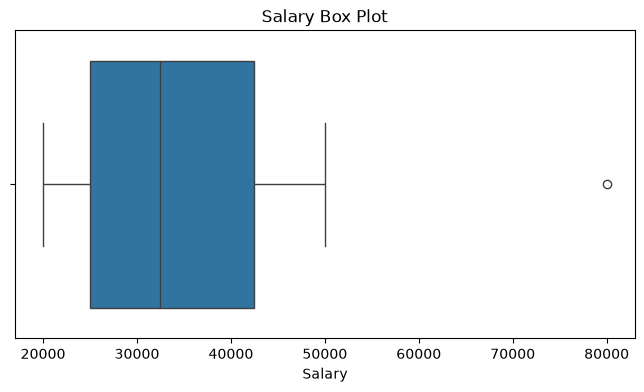

In [17]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["Salary"])

plt.xlabel("Salary")
plt.title("Salary Box Plot")

plt.show()

Interpretation: A point beyond the whiskers is a potential outlier, not automatically an error. Investigate it before deciding how to handle it.

#### Complete Univariate Analysis Code

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Salary": [20000, 25000, 25000, 30000, 35000, 40000, 50000, 80000]
}

df = pd.DataFrame(data)

# Descriptive Statistics
print("Mean:", df["Salary"].mean())
print("Median:", df["Salary"].median())
print("Mode:", df["Salary"].mode().tolist())
print("Minimum:", df["Salary"].min())
print("Maximum:", df["Salary"].max())
print("Range:", df["Salary"].max() - df["Salary"].min())
print("Variance:", df["Salary"].var())
print("Standard Deviation:", df["Salary"].std())
print("Q1:", df["Salary"].quantile(0.25))
print("Q2:", df["Salary"].quantile(0.50))
print("Q3:", df["Salary"].quantile(0.75))
print("90th Percentile:", df["Salary"].quantile(0.90))
print("Skewness:", df["Salary"].skew())
print("Kurtosis:", df["Salary"].kurt())

# Histogram
plt.figure(figsize=(8, 5))
plt.hist(df["Salary"], bins=5, edgecolor="black")
plt.title("Salary Histogram")
plt.xlabel("Salary")
plt.ylabel("Frequency")
plt.show()

# KDE / Density Plot
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="Salary", fill=True)
plt.title("Salary Density Plot")
plt.xlabel("Salary")
plt.show()

# Box Plot
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Salary"])
plt.title("Salary Box Plot")
plt.show()

#### Categorical Variables


**Create the Dataset**

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
data = {
    "Employee_ID": range(101, 121),

    "Department": [
        "IT", "HR", "Finance", "IT", "Sales",
        "IT", "HR", "Sales", "Finance", "IT",
        "Sales", "IT", "HR", "Finance", "Sales",
        "IT", "Finance", "HR", "IT", "Sales"
    ],

    "Gender": [
        "Male", "Female", "Male", "Female", "Male",
        "Male", "Female", "Female", "Male", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Female", "Male", "Male"
    ],

    "Employment_Type": [
        "Full-time", "Part-time", "Full-time", "Full-time",
        "Contract", "Full-time", "Part-time", "Contract",
        "Full-time", "Full-time", "Contract", "Full-time",
        "Part-time", "Full-time", "Contract", "Full-time",
        "Full-time", "Part-time", "Full-time", "Contract"
    ],

    "Education_Level": [
        "Bachelor", "Master", "Bachelor", "Master", "Bachelor",
        "Master", "Bachelor", "Bachelor", "PhD", "Bachelor",
        "Master", "Bachelor", "Master", "Bachelor", "Bachelor",
        "PhD", "Master", "Bachelor", "Master", "Bachelor"
    ]
}

df = pd.DataFrame(data)

display(df)

,Employee_ID,Department,Gender,Employment_Type,Education_Level
0,101,IT,Male,Full-time,Bachelor
1,102,HR,Female,Part-time,Master
2,103,Finance,Male,Full-time,Bachelor
3,104,IT,Female,Full-time,Master
4,105,Sales,Male,Contract,Bachelor
5,106,IT,Male,Full-time,Master
6,107,HR,Female,Part-time,Bachelor
7,108,Sales,Female,Contract,Bachelor
8,109,Finance,Male,Full-time,PhD
9,110,IT,Male,Full-time,Bachelor


#### Analysis

#### Frequency

Frequency is the number of times a particular category appears in a dataset.

For example, if the IT department contains 7 employees, the frequency of the IT category is 7.

In [20]:
df["Department"].value_counts()  #By default, value_counts() sorts categories from highest frequency to lowest frequency.

Department
IT         7
Sales      5
HR         4
Finance    4
Name: count, dtype: int64

In [21]:
df["Department"].value_counts(sort=False)

Department
IT         7
HR         4
Finance    4
Sales      5
Name: count, dtype: int64

#### AI/ML Application

Frequency analysis helps you understand how observations are distributed across categories. For example, it can reveal whether a customer dataset contains more customers from one region than another.

#### Unique Values

Definition: Unique values are the distinct categories present in a column, without counting repeated occurrences multiple times.

In [22]:
df["Department"].unique()

<ArrowStringArray>
['IT', 'HR', 'Finance', 'Sales']
Length: 4, dtype: str

In [23]:
#Count the Number of Unique Values
df["Department"].nunique()

4

In [24]:
##Check Unique Values for All Categorical Columns
categorical_columns = [
    "Department",
    "Gender",
    "Employment_Type",
    "Education_Level"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Department:
<ArrowStringArray>
['IT', 'HR', 'Finance', 'Sales']
Length: 4, dtype: str

Gender:
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

Employment_Type:
<ArrowStringArray>
['Full-time', 'Part-time', 'Contract']
Length: 3, dtype: str

Education_Level:
<ArrowStringArray>
['Bachelor', 'Master', 'PhD']
Length: 3, dtype: str


#### AI/ML Application

Unique-value analysis helps identify the number of categories that may need encoding before training a machine learning model.

For example, a department feature with four categories may be suitable for one-hot encoding, depending on the model and task.

#### Value Counts

Definition: The value_counts() method counts the occurrences of each unique value in a Series and returns the results as a frequency table.

We used it earlier to analyze department frequency. Now let's apply it to different categorical variables.

In [29]:
categorical_columns = [
    "Department",
    "Gender",
    "Employment_Type",
    "Education_Level"
]

for i in categorical_columns:
    print(i)
    print("\n",df[i].value_counts())



Department

 Department
IT         7
Sales      5
HR         4
Finance    4
Name: count, dtype: int64
Gender

 Gender
Male      11
Female     9
Name: count, dtype: int64
Employment_Type

 Employment_Type
Full-time    11
Contract      5
Part-time     4
Name: count, dtype: int64
Education_Level

 Education_Level
Bachelor    11
Master       7
PhD          2
Name: count, dtype: int64


#### AI/ML Application

value_counts() is useful for identifying class imbalance in classification datasets.

For example, if a fraud-detection dataset contains 9,900 normal transactions and only 100 fraudulent transactions, frequency analysis reveals that the classes are highly imbalanced.

#### Percentage Distribution

Definition: Percentage distribution represents the proportion of observations belonging to each category as a percentage of the total observations.

Percentage=  Category Frequency  /  Total Observations ×100


Our dataset contains 20 employees, of whom 7 belong to the IT department.

$$ \text{IT Percentage}=\frac{7}{20}\times100=35\% $$

Therefore, 35% of the employees in this sample belong to IT.

In [30]:
df["Department"].value_counts(normalize=True) * 100

Department
IT         35.0
Sales      25.0
HR         20.0
Finance    20.0
Name: proportion, dtype: float64

In [31]:
(df["Department"].value_counts(normalize=True) * 100).round(2)  #Round Percentages to Two Decimal Places

Department
IT         35.0
Sales      25.0
HR         20.0
Finance    20.0
Name: proportion, dtype: float64

#### Visualizations
#### Bar Chart

A bar chart displays categorical data using rectangular bars, with each bar representing a category and its frequency or another numerical measure.

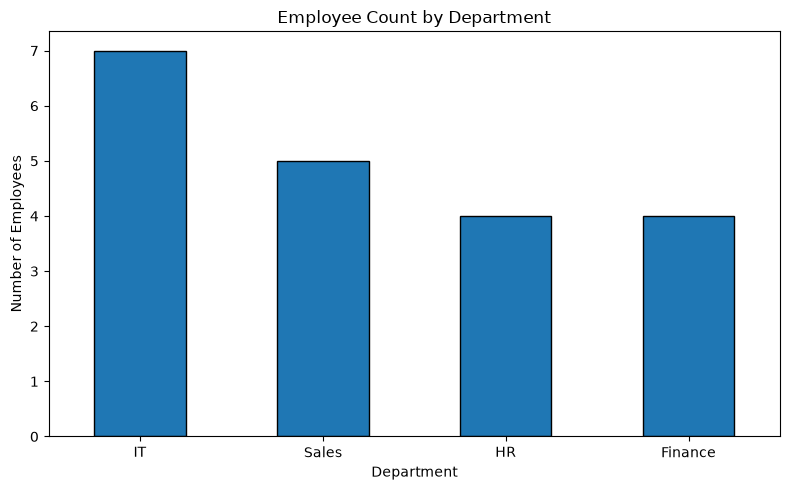

In [34]:
department_counts = df["Department"].value_counts()

department_counts.plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

####  Count Plot

A count plot is a categorical visualization that displays the number of observations in each category.

Seaborn's countplot() calculates the counts automatically from the supplied data.



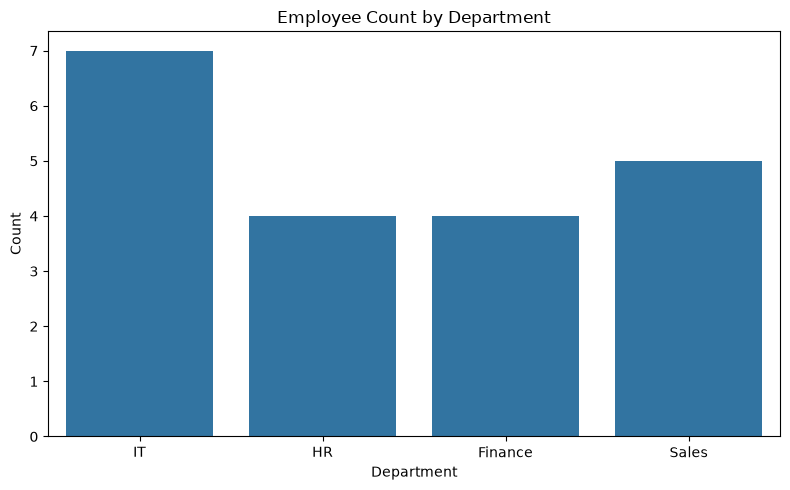

In [35]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Department"
)

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

#### Pie Chart

A pie chart represents categories as slices of a circle, with each slice showing its proportion of the total.

Pie charts are most useful when there are only a few categories and the categories represent parts of a meaningful whole.

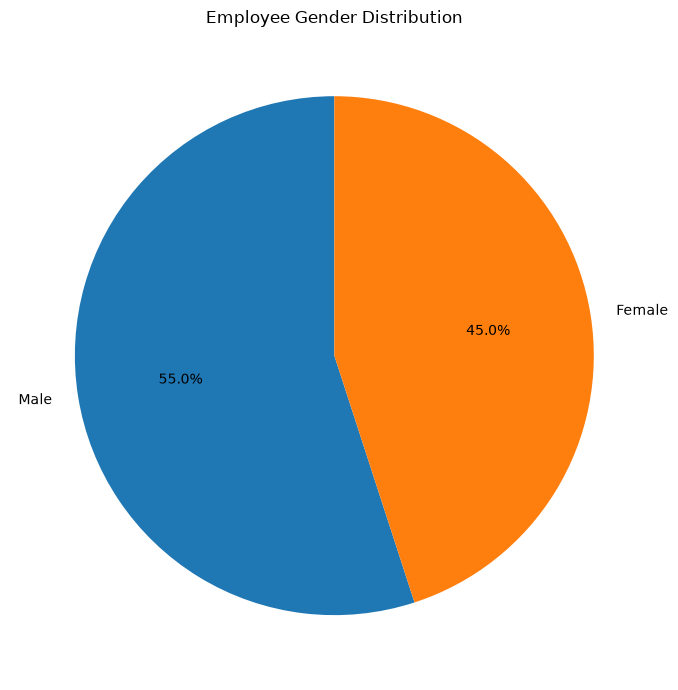

In [36]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Employee Gender Distribution")
plt.tight_layout()
plt.show()

In [ ]:
#### Code for Categorical EDA

In [ ]:
categorical_columns = [
    "Department",
    "Gender",
    "Employment_Type",
    "Education_Level"
]

for col in categorical_columns:

    print(f"\n{'=' * 40}")
    print(f"Column: {col}")
    print(f"{'=' * 40}")

    # Unique values
    print("\nUnique Values:")
    print(df[col].unique())

    # Number of unique values
    print("\nNumber of Unique Values:")
    print(df[col].nunique())

    # Frequency distribution
    print("\nFrequency Distribution:")
    print(df[col].value_counts())

    # Percentage distribution
    print("\nPercentage Distribution:")
    print(
        (df[col].value_counts(normalize=True) * 100).round(2)
    )

| S.No. | Task                              | Pandas / Python Code                                              |
| ----: | --------------------------------- | ----------------------------------------------------------------- |
|     1 | Identify unique values            | `df["Department"].unique()`                                       |
|     2 | Count unique values               | `df["Department"].nunique()`                                      |
|     3 | Calculate frequency               | `df["Department"].value_counts()`                                 |
|     4 | Calculate percentage distribution | `df["Department"].value_counts(normalize=True) * 100`             |
|     5 | Create a bar chart                | `df["Department"].value_counts().plot(kind="bar")`                |
|     6 | Create a count plot               | `sns.countplot(data=df, x="Department")`                          |
|     7 | Create a pie chart                | `df["Gender"].value_counts().plot(kind="pie", autopct="%1.1f%%")` |
